In [2]:
from __future__ import annotations
from typing import Literal

import sys,os
sys.path.insert(0, os.path.abspath(".."))

import time
import diffrax
import equinox as eqx  # https://github.com/patrick-kidger/equinox
import jax
import jax.nn as jnn
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import optax  # https://github.com/deepmind/optax
import pandas as pd

from ude import (
    NDE, ODE_LV_core, UDE, OdeProblem, UDE_Community, 
    train_model, dataloader,
)

In [3]:
class Coculture_Final_Model (eqx.Module):
    
    """
        State Vector ( Components)
                --------------------------------
                Se: S. elongatus
                Um: U. maydis
                Suc: Sucrose
                N: Nitrogen
                P1: Parameter1
                Met1: Metabolite1
                Met2: Metabolite2
            
            Parameter vectors
                ---------------------------------
                    
                    parameters_Se: Array
                    -----------------------------
                    u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se,
                    beta_Suc_Se, k_Met1_Se, beta_Met2_Se, k_P1_Met2_Se, K_I_pH_Suc_exp
                     
                    parameters_Um: Array
                    -----------------------------
                    u_max_Um, k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um,
                    e_Um, beta_Met1_Um, K_I_Met1_Um, K_I_Met2_Um, k_Met2_Um
                    
                    parameters_abiotic: Array
                    -----------------------------
                    L_0, Suc_Feed
                
            
            weights: Array
    """
    parameters_Se: Array
    parameters_Um: Array
    parameters_abiotic: Array

    def __call__(self, t: float, variables: Array, args) -> Array:
        
        # parameters and variables:
        # ----------------------------------------------------
        Se,Um,Suc,N,P1,Met1,Met2, = variables
        u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se, alpha_Suc_Se, k_Met1_Se, Y_Se_Met1, beta_Met2_Se = self.parameters_Se
        u_max_Um,k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um, e_Um, beta_Met1_Um, K_I_Met1_Um, K_I_Met2_Um = self.parameters_Um
        L_0, e_medium, = self.parameters_abiotic
    
        # derived
        L = L_0 * jnp.exp(-Se*e_Se - Um*e_Um - e_medium)
        
        # growth of Se
        u_Se    = u_max_Se * (L / (k_L_Se + L)) * (N / (k_N_Se + N)) * (1 + (Met1 / (k_Met1_Se + Met1)))
        Met1_imp_Se = Se * u_Se * (Met1 / (k_Met1_Se + Met1)) / Y_Se_Met1
        Suc_exp_Se  = Se * alpha_Suc_Se * L
        
        # growth of Um
        u_Um    = u_max_Um * (Suc / (k_Suc_Um + Suc)) * (N / (k_N_Um + N)) * (K_I_Met2_Um / (K_I_Met2_Um + Met2))
        Suc_imp_Um = u_Um * Um * 1/Y_Um_Suc
        Met1_exp_Um = Um * u_Um * beta_Met1_Um * (K_I_Met1_Um / (Met1 + K_I_Met1_Um))
        
        # change of variables
        #---------------------------------------------------------
        # microbes
        dSedt       = Se * (u_Se - k_death_Se)
        dUmdt       = Um * (u_Um - k_death_Um)

        
        # paramters, metabolites, etc. (ressources)
        dSucdt      = Suc_exp_Se - Suc_imp_Um
        dNdt        = - u_Se * Se * 1/Y_Se_N - u_Um * Um * 1/Y_Um_N
        dP1dt       = 0.0
        dMet1dt     = Met1_exp_Um - Met1_imp_Se
        dMet2dt     = 0.0
        
        

        return jnp.array([dSedt,dUmdt,dSucdt,dNdt,dP1dt,dMet1dt,dMet2dt])

In [4]:
def display_ODE_coculture(t_steps, ode_solution, display_variabs, ax, line="-", std=0):
    
    variables_dict = {
        "Se":  ["S. elongatus", 0, "blue"],
        "Um":  ["U. maydis", 1, "green"],
        "Suc": ["Sucrose",3, "gray"], 
        "N" :  ["Nitrogen",4, "red"],
        "P1":  ["Parameter 1",5, "brown"],
        "Met1": ["Metabolite 1",6, "yellow"], 
        "Met2": ["Metabolite 2",7, "olive"],
    }
    
    for var in display_variabs:
        ax.plot(
            t_steps,
            ode_solution[:,variables_dict[var][1]],
            color= variables_dict[var][2],
            label= variables_dict[var][0],
            linestyle=line
        )
        ax.fill_between (
            t_steps,
            ode_solution[:,variables_dict[var][1]]*(1+std),
            ode_solution[:,variables_dict[var][1]]*(1-std),
            alpha=0.3,
            linewidth=0,
            color= variables_dict[var][2],
            label= variables_dict[var][0],
            linestyle=line
        )

In [5]:
PARAMETERSET_COMMUNITY_Se = [
    # S. elongatus
    0.15,       # u_max_Se
    1,          # k_L_Se
    1,          # e_Se
    0.3,        # k_N_Se
    10.0,       # Y_Se_N
    0.005,      # k_death_Se
    0.1,        # alpha_Suc_Se
    0.01,        # k_Met1_Se
    7,          # Y_Se_Met1
    0.001,       # beta_Met2_Se
]
u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se, alpha_Suc_Se, k_Met1_Se, Y_Se_Met1, beta_Met2_Se = PARAMETERSET_COMMUNITY_Se
 

PARAMETERSET_COMMUNITY_Um = [
    # U.maydis
    0.1,    # u_max_Um
    0.15,   # k_Suc_Um
    0.2,   # Y_Um_Suc
    0.1,    # k_N_Um
    5.0,   # Y_N_Um
    0.002,  # k_death_Um
    0.3,    # e_Um
    0.9,    # beta_Met1_Um
    0.5,    # K_I_Met1_Um
    0.08,    # K_I_Met2_Um
]

(u_max_Um,k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um, e_Um, beta_Met1_Um, 
 K_I_Met1_Um, K_I_Met2_Um,) = PARAMETERSET_COMMUNITY_Um


PARAMETERSET_COMMUNITY_abiotic = [
    1,     # L0
    0.1,   # e_medium
]

STARTCONDITION_Medium = [
    0.0,    # S. elongatus
    0.00,   # U.maydis
    3,   # Sucrose
    3,      # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]


STARTCONDITION_COMMUNITY=[  
    0.1,    # S. elongatus
    0.01,    # U.maydis
    0.01,   # Sucrose
    5,      # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Axenic_Um = [
    0.0,     # S. elongatus
    0.01,    # U.maydis
    3,       # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Coculture_Se_Um = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Coculture_Se_Um = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Coculture_Se_Um_P1 = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # Sucrose
    5,       # Nitrogen
    1.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2 
]

STARTCONDITION_Axenic_Se = [
    0.1,     # S. elongatus
    0.0,    # U.maydis
    0.0,     # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Axenic_Se_N_low = [
    0.1,     # S. elongatus
    0.00,    # U.maydis
    0.0,     # Sucrose
    1,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2 
]

STARTCONDITION_Axenic_Se_Met1_Met2 = [
    0.1,     # S. elongatus
    0.00,    # U.maydis
    0.0,     # Sucrose
    5.0,     # Nitrogen
    1.0,     # Parameter1
    0.2,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Axenic_Se_P1 = [
    0.1,     # S. elongatus
    0.00,    # U.maydis
    0.0,     # Sucrose
    5.0,     # Nitrogen
    1.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Axenic_Um_N_low = [
    0.0,     # S. elongatus
    0.01,    # U.maydis
    3,       # Sucrose
    1,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

STARTCONDITION_Axenic_Um_Met2 = [
    0.0,     # S. elongatus
    0.01,    # U.maydis
    3,       # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.3,     # Metabolite2
]

STARTCONDITION_Coculture_low_N = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # Sucrose
    1,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
]

start_conditions_dict = {
    "Medium": STARTCONDITION_Medium,
    "Axenic_Se": STARTCONDITION_Axenic_Se,
    "Axenic_Se_N_low": STARTCONDITION_Axenic_Se_N_low,
    "Axenic_Um": STARTCONDITION_Axenic_Um,
    "Axenic_Um_N_low": STARTCONDITION_Axenic_Um_N_low,
    "Axenic_Se_Met1_Met2": STARTCONDITION_Axenic_Se_Met1_Met2,
    "Axenic_Se_P1": STARTCONDITION_Axenic_Se_P1,
    "Axenic_Um_Met2": STARTCONDITION_Axenic_Um_Met2,
    "Coculture_Se_Um": STARTCONDITION_Coculture_Se_Um,
    "Coculture_Se_Um_P1": STARTCONDITION_Coculture_Se_Um_P1,
    "Coculture_low_N": STARTCONDITION_Coculture_low_N,
}
all=["Se","Um","Suc","N","P1","Met1","Met2"]
conditions_df = pd.DataFrame.from_dict(start_conditions_dict, orient="index", columns=["Se","Um","Suc","N","P1","Met1","Met2"])
conditions_df

,Se,Um,Suc,N,P1,Met1,Met2
Medium,0.0,0.00,3.0,3.0,0.0,0.0,0.0
Axenic_Se,0.1,0.00,0.0,5.0,0.0,0.0,0.0
Axenic_Se_N_low,0.1,0.00,0.0,1.0,0.0,0.0,0.0
Axenic_Um,0.0,0.01,3.0,5.0,0.0,0.0,0.0
Axenic_Um_N_low,0.0,0.01,3.0,1.0,0.0,0.0,0.0
Axenic_Se_Met1_Met2,0.1,0.00,0.0,5.0,1.0,0.2,0.0
Axenic_Se_P1,0.1,0.00,0.0,5.0,1.0,0.0,0.0
Axenic_Um_Met2,0.0,0.01,3.0,5.0,0.0,0.0,0.3
Coculture_Se_Um,0.1,0.01,0.0,5.0,0.0,0.0,0.0
Coculture_Se_Um_P1,0.1,0.01,0.0,5.0,1.0,0.0,0.0


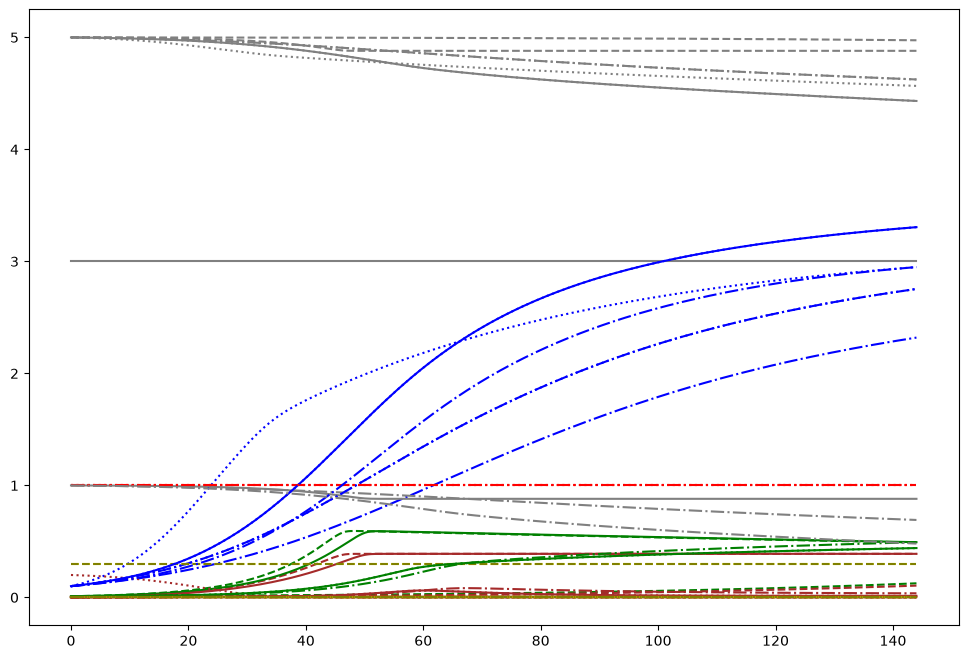

In [27]:
coculture_ODE = Coculture_Final_Model(PARAMETERSET_COMMUNITY_Se, PARAMETERSET_COMMUNITY_Um, PARAMETERSET_COMMUNITY_abiotic)
ODE_Problem_Coculture = OdeProblem(
    coculture_ODE,
    full_state=True,
    rtol= 1e-3,
    atol=1e-6,
    max_steps=300000
)

t_steps = jnp.linspace(0, 144, 300)

fig, axs = plt.subplots(1, 1, figsize=(12,8))
linesstyles = ["-", ":", "-.", "--",]
i=0

for name,start_condition in conditions_df.iterrows():
    linestyle = i%4
    ys=ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys,
        all, axs, line=linesstyles[linestyle])
    i += 1 

In [28]:
# generate noise:
def get_timepoint_indices (time_in_hours: list):
    indices=[]
    for x, timepoint in enumerate(time_in_hours):
        indices.append(int(200/150*timepoint))
    return jnp.array(indices)

def add_noise (data:Array, std_dev, key):
    return data*(1+std_dev*jr.normal(key,data.shape)) 
    
six=get_timepoint_indices([0,24,48,72,96,144])
ten=get_timepoint_indices([0,8,24,32,48,56,72,80,96,144])
twentyfour=get_timepoint_indices(jnp.linspace(0,144,24))


In [22]:
t_steps = jnp.linspace(0, 144, 300)

key_1 = jr.PRNGKey(42)
list_ys=[]
list_y0=[]
for name,start_condition in conditions_df.iterrows():
    ys=ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
    ys_noise = add_noise(ys[twentyfour,:], 0.05 ,key_1)
    list_ys.append(ys_noise)
    list_y0.append(ys_noise[0])
    
data_train= jnp.array(list_ys)
ts_train= t_steps[twentyfour]
y0_full = jnp.array(list_y0)

max_values = jnp.max(data_train, axis=(0,1))
scale = jnp.where(max_values == 0, 1.0, max_values)

scale
print("scale:", scale)
print("type:", type(scale))

scale: [2.9186854  0.6316891  3.1585183  5.3731194  1.1202509  0.4155244
 0.31703407]
type: <class 'jaxlib._jax.ArrayImpl'>


In [11]:
class NSM(eqx.Module):
    
    """
    Reconstruction of an easy form of NSM
    
    """
    nde: eqx.Module
    parameters: Array

    def __init__(
        self,
        nde: eqx.Module,
        parameters: Array,  
    ) -> None:
        
        self.nde = nde
        self.parameters = parameters

    # ------------------------------------------------------------------
    # Forward pass
    # ------------------------------------------------------------------

    def __call__(self, t: float, y: Array, args) -> Array:
        """Evaluate the UDE vector field at time ``t`` and state ``y``."""
        
        (P_S1_M1, P_S2_M1, C_S1_M1, C_S2_M1, b_M1, 
        P_S1_M2, P_S2_M2, C_S1_M2,C_S2_M2, b_M2,
        P_S1_M3, P_S2_M3, C_S1_M3, C_S2_M3, b_M3, 
        P_S1_M4, P_S2_M4, C_S1_M4, C_S2_M4, b_M4) = self.parameters
        
        def soft10(x: float) -> float:
            """Calcultates the softplus function with base 10."""
            return jnp.log10(1 + jnp.exp(x))
        
        nde_out = self.nde(t, y, args)
        S1 = y[0]
        S2 = y[1]
        M1 = y[2]
        M2 = y[3]
        P1 = y[4]
        M3 = y[5]
        M4 = y[6]
        
        dS1dt = S1 * nde_out[0]
        dS2dt = S2 * nde_out[1]
        dM1dt = jax.nn.softplus(nde_out[2]) * (S1 * soft10(P_S1_M1) + S2 * soft10(P_S2_M1) - M1 * (S1 * soft10(C_S1_M1) + S2 * soft10(C_S2_M1) + soft10(b_M1)))
        dM2dt = jax.nn.softplus(nde_out[3]) * (S1 * soft10(P_S1_M2) + S2 * soft10(P_S2_M2) - M2 * (S1 * soft10(C_S1_M2) + S2 * soft10(C_S2_M2) + soft10(b_M2)))
        dP1dt = 0.0
        dM3dt = jax.nn.softplus(nde_out[5]) * (S1 * soft10(P_S1_M3) + S2 * soft10(P_S2_M3) - M3 * (S1 * soft10(C_S1_M3) + S2 * soft10(C_S2_M3) + soft10(b_M3)))
        dM4dt = jax.nn.softplus(nde_out[6]) * (S1 * soft10(P_S1_M4) + S2 * soft10(P_S2_M4) - M4 * (S1 * soft10(C_S1_M4) + S2 * soft10(C_S2_M4) + soft10(b_M4)))

        return jnp.array([dS1dt,dS2dt,dM1dt,dM2dt,dP1dt,dM3dt,dM4dt])

In [24]:
nde = NDE(7,7,16,2, key = key_1)
param= jr.normal(key_1, (20,)) # initialization as in NSM Paper with gaussian around zero
nsm = NSM(nde, param)
nsm_problem = OdeProblem(
    nsm,
    full_state=True,
    rtol= 1e-4,
    atol=1e-6,
    max_steps=300000
)

# startcondition = conditions_df.loc["Coculture_Se_Um"]
# ODE_Problem_Coculture(t_steps, startcondition)
# data_train = ODE_training

In [25]:
nsm_trained = train_model(
    nsm_problem,
    data=data_train,          # shape (11, T_train, 2)
    y0=y0_full,               # shape (11, 7)
    ts_train=ts_train,
    loader_key= key_1,
    steps_strategy=(2000,),
    length_strategy=(1.0,),
    learning_rate=1e-4,
    print_every=1,
    scale=scale,
)


── Phase 1/1 (2000 steps, t ∈ [0.00, 92.47]) ──
  Step     0 | Loss 0.040716 | Time 2.650s
  Step     1 | Loss 0.056208 | Time 2.551s
  Step     2 | Loss 0.158119 | Time 0.004s
  Step     3 | Loss 0.170386 | Time 0.003s
  Step     4 | Loss 0.188638 | Time 0.005s
  Step     5 | Loss 0.345226 | Time 0.003s
  Step     6 | Loss 0.175784 | Time 0.003s
  Step     7 | Loss 0.160155 | Time 0.003s
  Step     8 | Loss 0.282799 | Time 0.005s
  Step     9 | Loss 0.159821 | Time 0.003s
  Step    10 | Loss 0.175459 | Time 0.003s
  Step    11 | Loss 0.159812 | Time 0.004s
  Step    12 | Loss 0.175449 | Time 0.003s
  Step    13 | Loss 0.175751 | Time 0.003s
  Step    14 | Loss 0.040692 | Time 0.004s
  Step    15 | Loss 0.158065 | Time 0.003s
  Step    16 | Loss 0.056183 | Time 0.003s
  Step    17 | Loss 0.160103 | Time 0.004s
  Step    18 | Loss 0.188611 | Time 0.004s
  Step    19 | Loss 0.170334 | Time 0.003s
  Step    20 | Loss 0.282732 | Time 0.003s
  Step    21 | Loss 0.345118 | Time 0.005s
  Ste

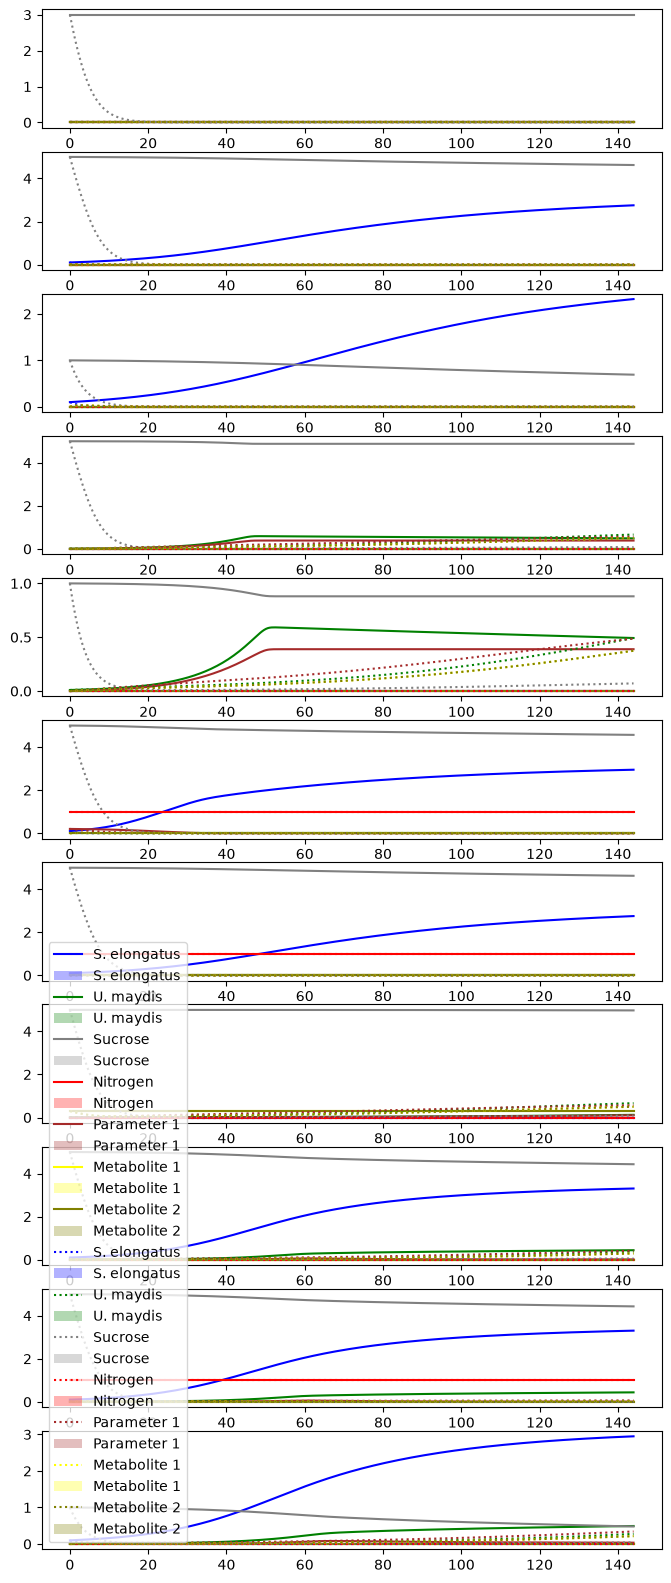

In [26]:
t_steps = jnp.linspace(0, 144, 300)

fig, axs = plt.subplots(11, 1, figsize=(8,20))
i=0

for name,start_condition in conditions_df.iterrows():
    ys=ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys,
        all, axs[i], line="-")
    ys_nsm=nsm_trained(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys_nsm,
            all, axs[i], line=":")
    i += 1 
plt.legend()

### training on one row first

In [15]:
data_train[:,0].shape

(11, 7)

In [ ]:
data_train = jnp.array([data_train[1]])
y0_full = data_train[:,0]

nsm_trained = train_model(
    nsm_problem,
    data=data_train,          # shape (11, T_train, 2)
    y0=y0_full,               # shape (11, 7)
    ts_train=ts_train,
    loader_key= key_1,
    steps_strategy=(2000,),
    length_strategy=(1.0,),
    learning_rate=1e-4,
    print_every=1,
    scale=scale,
)


── Phase 1/1 (2000 steps, t ∈ [0.00, 92.47]) ──
  Step     0 | Loss 0.159841 | Time 10.200s
  Step     1 | Loss 0.159840 | Time 7.877s
  Step     2 | Loss 0.159840 | Time 0.015s
  Step     3 | Loss 0.159839 | Time 0.014s
  Step     4 | Loss 0.159839 | Time 0.014s
  Step     5 | Loss 0.159838 | Time 0.016s
  Step     6 | Loss 0.159837 | Time 0.014s
  Step     7 | Loss 0.159837 | Time 0.014s
  Step     8 | Loss 0.159836 | Time 0.013s
  Step     9 | Loss 0.159835 | Time 0.015s
  Step    10 | Loss 0.159834 | Time 0.012s
  Step    11 | Loss 0.159834 | Time 0.013s
  Step    12 | Loss 0.159833 | Time 0.013s
  Step    13 | Loss 0.159832 | Time 0.012s
  Step    14 | Loss 0.159831 | Time 0.013s
  Step    15 | Loss 0.159830 | Time 0.013s
  Step    16 | Loss 0.159829 | Time 0.012s
  Step    17 | Loss 0.159828 | Time 0.014s
  Step    18 | Loss 0.159827 | Time 0.012s
  Step    19 | Loss 0.159826 | Time 0.012s
  Step    20 | Loss 0.159825 | Time 0.009s
  Step    21 | Loss 0.159824 | Time 0.011s
  St

EquinoxRuntimeError: Above is the stack outside of JIT. Below is the stack inside of JIT:
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 758, in start
    self.io_loop.start()
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\tornado\platform\asyncio.py", line 211, in start
    self.asyncio_loop.run_forever()
  File "c:\Users\majas\anaconda3\envs\CompBioAc\Lib\asyncio\base_events.py", line 645, in run_forever
    self._run_once()
  File "c:\Users\majas\anaconda3\envs\CompBioAc\Lib\asyncio\base_events.py", line 1999, in _r

try again with multiple starting points?